# IAPH - TP2

## Consignas de resolución

El trabajo debe entregarse en formato Jupyter Notebook (.ipynb), asegurando que todas las celdas sean ejecutables y estén debidamente comentadas.

## 0.&nbsp;Instalo librerías y creo funciones generales.

In [ ]:
# Instalo las librerías necesarias para trabajar.
!pip install pymupdf pdfplumber -q

In [ ]:
# Importo las librerías necesarias para trabajar.
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import pdfplumber
import pymupdf
import requests

from collections import Counter
from IPython.display import HTML, display
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [ ]:
# Defino los estilos para los títulos.
style = """
<style>
    label {
        display: block;
        margin: 0 0 10px 0;
        font-family: "Trebuchet MS", sans-serif;
        font-size: 16px;
        font-weight: bold;
        line-height: 1.2;
    }
</style>
"""

# Defino una función para mostrar títulos en HTML.
def title(texto):
    display(HTML(f"{style}<label>{texto}</label>"))

## 1.&nbsp;Adquisición y metadatos

PDF seleccionado: **Informe sobre maquinarias y nuevas tecnologías AgTech (2021)**.
https://www.argentina.gob.ar/sites/default/files/informe-maquinarias-nuevas-tecnologias-agtech-magyp.pdf

### Descarga: Utilizando las librerías **requests** o urllib, descarga un archivo PDF desde un enlace público (por ejemplo, un artículo científico de arXiv o un reporte institucional).

No puede usar el mismo pdf o enlace que otra persona ya haya presentado en el foro. El PDF elegido debe contener texto extraible, no deben ser páginas escaneadas tipo imagen.

In [ ]:
# Defino la URL del archivo PDF.
url_pdf = "https://www.argentina.gob.ar/sites/default/files/informe-maquinarias-nuevas-tecnologias-agtech-magyp.pdf"

# Obtengo el nombre original del archivo desde la URL.
nombre_archivo = url_pdf.split("/")[-1]

# Realizo la solicitud HTTP.
respuesta = requests.get(url_pdf)

# Guardo el archivo descargado con su nombre original.
with open(nombre_archivo, "wb") as archivo:
    archivo.write(respuesta.content)

# Imprimo el título de la celda.
title("Datos:")

# Muestro información básica de la descarga.
print("Código de estado:", respuesta.status_code)
print("Tipo de contenido:", respuesta.headers.get("Content-Type"))
print("Nombre de archivo:", nombre_archivo)

Código de estado: 200
Tipo de contenido: application/pdf
Nombre de archivo: informe-maquinarias-nuevas-tecnologias-agtech-magyp.pdf


### Inspección: Muestra por pantalla los metadatos del archivo: título, autor, número de páginas y software de creación.

Sugerencia: Puedes utilizar librerías como **PyMuPDF** (fitz) o PyPDF2.

In [ ]:
# Abro el documento PDF.
documento = pymupdf.open(nombre_archivo)

# Obtengo los metadatos del documento.
metadatos = documento.metadata

# Imprimo el título de la celda.
title("Metadatos:")

# Muestro todos los metadatos disponibles.
for clave, valor in metadatos.items():
    print(f"{clave}: {valor}")

format: PDF 1.5
title: 
author: 
subject: 
keywords: 
creator: 
producer: fCoder PDF producer
creationDate: D:20211201102752-02'00'
modDate: D:20211201153032-03'00'
trapped: 
encryption: None


## 2.&nbsp;Análisis estructural del texto

### Extracción cruda: Extrae el texto del PDF.. Identifica la función de la librería elegida que te ayuda en esta tarea y te permite ver el texto extraído lo más crudo posible.

In [ ]:
# Extraigo el texto de la primera página.
texto_pagina = documento[0].get_text()

# Imprimo el título de la celda.
title("Primeros caracteres del texto:")

# Muestro los primeros caracteres del texto.
print(texto_pagina[:1500])

 
 
200 Millones de Toneladas de 
Cereales, Oleaginosas y Legumbres 
 
“La agricultura es la madre fecunda que proporciona todas las materias primeras que 
dan movimiento a las artes y el comercio”. Manuel Belgrano. 
 
 
Maquinarias y Nuevas Tecnologías        
‘Agtech’ 
 
Diciembre 2021 



### Análisis de separadores: Observa y describe cómo están separados los párrafos, las secciones y los capítulos.

In [ ]:
# Selecciono páginas representativas del documento mediante cuantiles.
cantidad_paginas = documento.page_count

cuantiles = [0, 0.25, 0.50, 0.75, 1]

paginas_muestra = [
    round(cuantil * (cantidad_paginas - 1))
    for cuantil in cuantiles
]

# Imprimo la cantidad de páginas del documento.
title(f"Cantidad de páginas: {cantidad_paginas}")

# Imprimo el título de la celda.
title("Fragmentos de páginas seleccionadas:")

# Muestro fragmentos de las páginas seleccionadas.
for indice_pagina in paginas_muestra:
    texto_pagina = documento[indice_pagina].get_text()

    print(f"\n--- Página {indice_pagina + 1} ---")
    print(repr(texto_pagina[:1000]))


--- Página 1 ---
' \n \n200 Millones de Toneladas de \nCereales, Oleaginosas y Legumbres \n \n“La agricultura es la madre fecunda que proporciona todas las materias primeras que \ndan movimiento a las artes y el comercio”. Manuel Belgrano. \n \n \nMaquinarias y Nuevas Tecnologías        \n‘Agtech’ \n \nDiciembre 2021 \n'

--- Página 11 ---
'Maquinarias y Nuevas Tecnologías ‘AgTech’ \n \n10\nDe acuerdo a lo comentado hasta aquí, es claro el beneficio de aplicar esta tecnología \npara el productor, ya que se hace cargo de los costos de producción gestionándolos \nracionalmente y eso se traduce en una mejora en la renta de la cosecha. Ahora bien, \ncuando se trata de analizar esta inversión desde la conveniencia del contratista, la \nsituación es más compleja porque el productor no siempre está dispuesto a reconocerle la \nutilización de esta tecnología a través de un mayor precio en la tarifa con lo cual se le \ncomplica su amortización. Por ello sería muy importante que los contratista

### Identificación de caracteres: ¿Qué caracteres especiales funcionan como separadores de línea o de bloque en este archivo específico?

(Ej: \n, \r, \t o secuencias de espacios).

In [ ]:
# Extraigo el texto completo del documento.
texto_completo = ""

for pagina in documento:
    texto_completo += pagina.get_text()

# Organizo los separadores y sus cantidades en una tabla.
separadores = {
    "Separador": [
        "Saltos de línea (\\n)",
        "Retornos de carro (\\r)",
        "Tabulaciones (\\t)",
        "Saltos de línea dobles (\\n\\n)",
        "Saltos de línea con espacio (\\n \\n)",
        "Saltos de línea triples (\\n\\n\\n)",
        "Saltos de línea con dos espacios (\\n  \\n)",
        "Espacios dobles",
        "Espacios triples",
        "Secuencias de cuatro espacios"
    ],
    "Cantidad": [
        texto_completo.count("\n"),
        texto_completo.count("\r"),
        texto_completo.count("\t"),
        texto_completo.count("\n\n"),
        texto_completo.count("\n \n"),
        texto_completo.count("\n\n\n"),
        texto_completo.count("\n  \n"),
        texto_completo.count("  "),
        texto_completo.count("   "),
        texto_completo.count("    ")
    ]
}

# Imprimo el título de la celda.
title("Separadores:")

# Creo y muestro el DataFrame.
dataframe_separadores = pd.DataFrame(separadores)
dataframe_separadores

,Separador,Cantidad
0,Saltos de línea (\n),1477
1,Retornos de carro (\r),0
2,Tabulaciones (\t),0
3,Saltos de línea dobles (\n\n),0
4,Saltos de línea con espacio (\n \n),79
5,Saltos de línea triples (\n\n\n),0
6,Saltos de línea con dos espacios (\n \n),6
7,Espacios dobles,167
8,Espacios triples,35
9,Secuencias de cuatro espacios,19


## 3.&nbsp;Extracción de datos tabulares

### Busca una página en el PDF que contenga una tabla de datos.

In [ ]:
# Busco tablas en todas las páginas del documento.
paginas_con_tablas = []

with pdfplumber.open(nombre_archivo) as pdf:
    for numero_pagina, pagina in enumerate(pdf.pages, start=1):
        tablas = pagina.extract_tables()

        if tablas:
            paginas_con_tablas.append({
                "Página": numero_pagina,
                "Cantidad": len(tablas)
            })

# Imprimo el título de la celda.
title("Páginas con tablas:")

# Creo y muestro el DataFrame.
dataframe_tablas = pd.DataFrame(paginas_con_tablas)
dataframe_tablas

,Página,Cantidad
0,17,1
1,23,1
2,36,1
3,37,1


### Extrae dicha tabla y conviértela en un DataFrame de Pandas.

Sugerencia: Se recomienda el uso de **pdfplumber** o tabula-py.

In [ ]:
# Extraigo la primera tabla detectada en el documento.
with pdfplumber.open(nombre_archivo) as pdf:
    tabla = None

    for pagina in pdf.pages:
        tablas = pagina.extract_tables()

        if tablas:
            tabla = tablas[0]
            break

# Convierto la tabla en un DataFrame.
dataframe = pd.DataFrame(tabla)

# Imprimo el título de la celda.
title("Tabla elegida:")

# Muestro la tabla extraída.
dataframe

,0,1,2,3,4,5
0,Zona del país,Unidades,Trigo,Maíz,Soja 1,Soja 2
1,Núcleo maicera,qq/ha,"42,39","90,56","39,14","25,3"
2,Oeste de Bs As,qq/ha,"37,11","79,33","30,8","21,82"
3,Sudoeste de Bs. As.,qq/ha,"30,29","59,38","20,36",
4,Sudeste de Bs. As.,qq/ha,"39,51","67,33","24,69","12,92"
5,Este de Bs. As.,qq/ha,"34,55","71,34","28,99","17,6"
6,Sur de Córdoba,qq/ha,"28,85","68,7","30,64","21,38"
7,Norte de Santa Fe,qq/ha,"26,38","61,49","24,42","20,5"
8,Entre Ríos,qq/ha,"28,4","64,41","22,44","16,55"
9,Santiago del Estero,qq/ha,"19,14","65,74","26,64","27,66"


### Realiza una limpieza básica de la tabla (nombrar columnas, eliminar filas vacías).

In [ ]:
# Creo una copia para trabajar con la tabla.
dataframe_improved = dataframe.copy()

# Asigno la primera fila como nombres de columna y la elimino de los datos.
dataframe_improved.columns = dataframe_improved.iloc[0]
dataframe_improved = dataframe_improved.iloc[1:].reset_index(drop=True)

# Elimino las filas completamente vacías.
dataframe_improved = dataframe_improved.dropna(how="all")

# Imprimo el título de la celda.
title("Tabla mejorada:")

# Reindexo y muestro la tabla limpia.
dataframe_improved = dataframe_improved.reset_index(drop=True)
dataframe_improved

,Zona del país,Unidades,Trigo,Maíz,Soja 1,Soja 2
0,Núcleo maicera,qq/ha,"42,39","90,56","39,14","25,3"
1,Oeste de Bs As,qq/ha,"37,11","79,33","30,8","21,82"
2,Sudoeste de Bs. As.,qq/ha,"30,29","59,38","20,36",
3,Sudeste de Bs. As.,qq/ha,"39,51","67,33","24,69","12,92"
4,Este de Bs. As.,qq/ha,"34,55","71,34","28,99","17,6"
5,Sur de Córdoba,qq/ha,"28,85","68,7","30,64","21,38"
6,Norte de Santa Fe,qq/ha,"26,38","61,49","24,42","20,5"
7,Entre Ríos,qq/ha,"28,4","64,41","22,44","16,55"
8,Santiago del Estero,qq/ha,"19,14","65,74","26,64","27,66"
9,Noa (Salta y NO de Stgo del Estero),qq/ha,"16,83","60,91","24,25","24,18"


## 4.&nbsp;Análisis de frecuencias (NLP básico)

Elige una página que contenga únicamente texto narrativo, usa la biblioteca nltk o spacy  y realiza lo siguiente:

### Tokenización: Extrae el texto y conviértelo a minúsculas.

In [ ]:
# Selecciono una página del documento.
indice_pagina = 2

# Extraigo el texto de la página seleccionada.
texto_narrativo = documento[indice_pagina].get_text()

# Imprimo el título de la celda.
title(f"Texto crudo de la página: {indice_pagina}")

# Muestro el texto procesado.
print(texto_narrativo)

Maquinarias y Nuevas Tecnologías ‘AgTech’ 
 
2
Situación actual, supuestos de la adopción de tecnología 
Existe consenso a la hora de establecer que la situación actual de la producción global de 
alimentos está caracterizada por dos escenarios. Por un lado, nos encontramos con el 
aumento de la población a nivel mundial, que actualmente ronda los 7.200 millones de 
habitantes y se estima que hacia el 2050 llegaría a los 9.000 millones de personas.  Este 
aumento de la población traerá aparejado una mayor demanda de alimentos que FAO 
estima cercana al 70%. 
El otro escenario está expresado por una sociedad que exige cambios al sector 
agroalimentario reclamando que realice “ajustes” para asegurar una producción 
sostenible, o sea aquella que permita satisfacer de manera continua y equitativa las 
crecientes necesidades de la población mundial focalizando varios aspectos por resolver y 
mejorar como el uso de los fitosanitarios, la deforestación o los monocultivos. Esta mirada 
acota l

In [ ]:
# Elimino las primeras tres líneas.
texto_sin_encabezado = texto_narrativo.splitlines()[3:]

# Uno nuevamente las líneas del texto sin encabezado y sin saltos de línea.
texto_limpio = " ".join(texto_sin_encabezado)

# Reemplazo doble espaciado por uno solo.
texto_limpio = texto_limpio.replace("  ", " ")

# Convierto el texto a minúsculas.
texto_limpio = texto_limpio.lower()

# Imprimo el título de la celda.
title("Texto limpio y en minúsculas:")

# Muestro el texto procesado.
print(texto_limpio)

situación actual, supuestos de la adopción de tecnología existe consenso a la hora de establecer que la situación actual de la producción global de alimentos está caracterizada por dos escenarios. por un lado, nos encontramos con el aumento de la población a nivel mundial, que actualmente ronda los 7.200 millones de habitantes y se estima que hacia el 2050 llegaría a los 9.000 millones de personas. este aumento de la población traerá aparejado una mayor demanda de alimentos que fao estima cercana al 70%. el otro escenario está expresado por una sociedad que exige cambios al sector agroalimentario reclamando que realice “ajustes” para asegurar una producción sostenible, o sea aquella que permita satisfacer de manera continua y equitativa las crecientes necesidades de la población mundial focalizando varios aspectos por resolver y mejorar como el uso de los fitosanitarios, la deforestación o los monocultivos. esta mirada acota los márgenes de tolerancia en temas vinculados a la contamina

### Limpieza: Elimina las stop words (palabras funcionales sin peso semántico como "el", "de", "y") y signos de puntuación.

In [ ]:
# Descargo los recursos necesarios de NLTK.
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
# Tokenizo el texto.
tokens = word_tokenize(texto_limpio, language="spanish")

# Obtengo las stop words en español.
stop_words = set(stopwords.words("spanish"))

# Elimino stop words y signos de puntuación.
tokens_limpios = [
    token
    for token in tokens
    if token not in stop_words and token.isalpha()
]

# Imprimo el título de la celda.
title("Primeros tokens resultantes:")

# Muestro los primeros tokens resultantes.
print(tokens_limpios[:50])

['situación', 'actual', 'supuestos', 'adopción', 'tecnología', 'existe', 'consenso', 'hora', 'establecer', 'situación', 'actual', 'producción', 'global', 'alimentos', 'caracterizada', 'dos', 'escenarios', 'lado', 'encontramos', 'aumento', 'población', 'nivel', 'mundial', 'actualmente', 'ronda', 'millones', 'habitantes', 'estima', 'hacia', 'llegaría', 'millones', 'personas', 'aumento', 'población', 'traerá', 'aparejado', 'mayor', 'demanda', 'alimentos', 'fao', 'estima', 'cercana', 'escenario', 'expresado', 'sociedad', 'exige', 'cambios', 'sector', 'agroalimentario', 'reclamando']


### Visualización: Genera un gráfico de barras que muestre las 15 palabras más frecuentes en esa página.

¿Te surgieron en esta visualización tokens que también considerarías stop words? Comenta y justifica.

In [ ]:
# Cuento la frecuencia de cada token.
frecuencias = Counter(tokens_limpios)

# Obtengo las 15 palabras más frecuentes.
top_15 = frecuencias.most_common(15)

# Organizo las palabras y sus frecuencias en una tabla.
dataframe_frecuencias = pd.DataFrame(
    top_15,
    columns=["Palabra", "Frecuencia"]
)

# Imprimo el título de la celda.
title("Top 15 palabras más frecuentes:")

# Muestro el DataFrame.
dataframe_frecuencias

,Palabra,Frecuencia
0,producción,7
1,situación,3
2,población,3
3,mundial,3
4,demanda,3
5,sector,3
6,degradación,3
7,ambiental,3
8,actual,2
9,alimentos,2


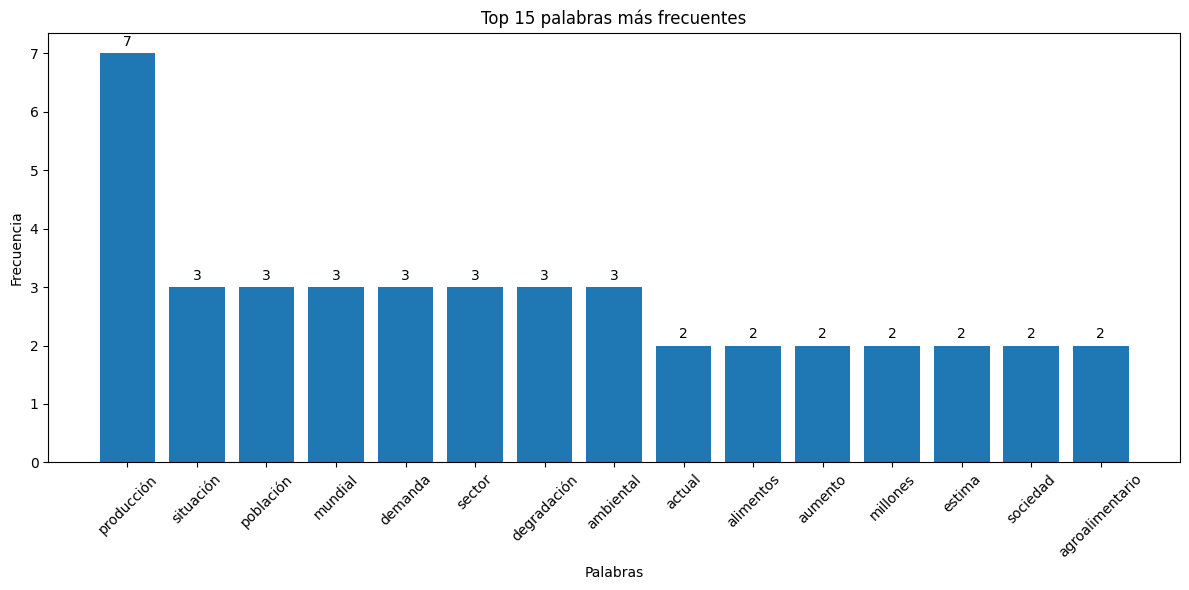

In [ ]:
# Separo las palabras y sus frecuencias.
palabras = [palabra for palabra, frecuencia in top_15]
frecuencias_palabras = [frecuencia for palabra, frecuencia in top_15]

# Genero el gráfico de barras.
plt.figure(figsize=(12, 6))
barras = plt.bar(palabras, frecuencias_palabras)

# Agrego los valores arriba de cada barra.
plt.bar_label(barras, padding=3)

# Agrego títulos y etiquetas.
plt.title("Top 15 palabras más frecuentes")
plt.xlabel("Palabras")
plt.ylabel("Frecuencia")

# Roto las etiquetas para mejorar la lectura.
plt.xticks(rotation=45)

# Muestro el gráfico.
plt.tight_layout()
plt.show()